# Visualização de Dados e Resultados Operacionais - Superstore
**Objetivo:** Explorar visualmente os dados tratados da Superstore para identificar oportunidades de aumento de margem, gargalos de lucro e o impacto real das políticas de desconto nas diferentes categorias de produtos.

## 1. Configuração do Ambiente e Importação dos Dados
Nesta etapa, importamos as bibliotecas de visualização (`seaborn` e `matplotlib`) e carregamos o nosso conjunto de dados previamente limpo e traduzido. Utilizamos parâmetros de data específicos para garantir que o sistema reconheça a nossa linha do tempo corretamente.

In [1]:
#Importando e visualizando o dataset
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Garantindo que as colunas fiquem no formato datetime
df = pd.read_csv("../data/processed/SampleSuperstore_Tratado.csv", parse_dates=['Data_Pedido', 'Data_Envio'])

df['Vendas'] = df['Vendas'].round(2)
df.head()

,ID,ID_Pedido,Data_Pedido,Data_Envio,Modo_Envio,ID_Cliente,Nome_Cliente,Segmento,Pais,Cidade,...,Regiao,ID_Produto,Categoria,Sub_Categoria,Nome_Produto,Vendas,Quantidade,Desconto,Lucro,Margem de Lucro %
0,1,CA-2016-152156,2016-11-08,2016-11-11,Segunda Classe,CG-12520,Claire Gute,Consumidor,Estados Unidos,Henderson,...,Sul,FUR-BO-10001798,Mobilia,Estantes,Bush Somerset Collection Bookcase,261.96,2,0.00,41.9136,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Segunda Classe,CG-12520,Claire Gute,Consumidor,Estados Unidos,Henderson,...,Sul,FUR-CH-10000454,Mobilia,Cadeiras,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.5820,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Segunda Classe,DV-13045,Darrin Van Huff,Corporativo,Estados Unidos,Los Angeles,...,Oeste,OFF-LA-10000240,Materiais de Escritorio,Etiquetas,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.8714,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Classe Padrao,SO-20335,Sean O'Donnell,Consumidor,Estados Unidos,Fort Lauderdale,...,Sul,FUR-TA-10000577,Mobilia,Mesas,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.0310,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Classe Padrao,SO-20335,Sean O'Donnell,Consumidor,Estados Unidos,Fort Lauderdale,...,Sul,OFF-ST-10000760,Materiais de Escritorio,Armazenamento,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.5164,11.25


## 2. Volume de Vendas por Categoria
O primeiro passo para entender o nosso negócio é mapear onde está concentrado o maior volume de dinheiro. O gráfico de barras abaixo classifica o total de vendas por categoria de produto.

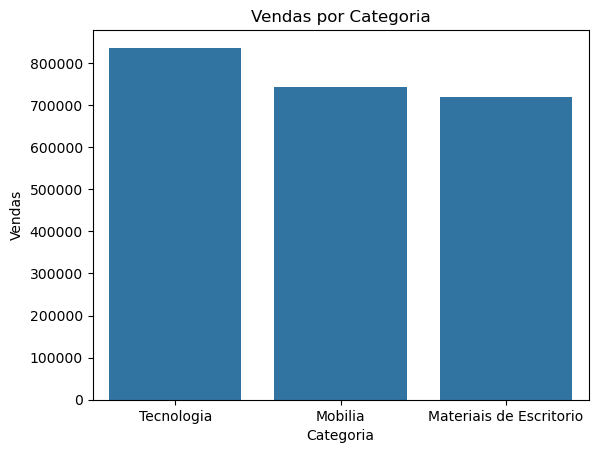

In [2]:
#Definindo o filtro do gráfico de Vendas por Categoria
vendas_cat = df.groupby('Categoria')['Vendas'].sum().sort_values(ascending=False).reset_index()

#Plotando o gráfico
graf_vendas_cat = sns.barplot(data = vendas_cat, x='Categoria', y='Vendas')
plt.title('Vendas por Categoria')
plt.show()

> **Observação:** Conseguimos visualizar claramente quais categorias lideram o faturamento da empresa, estabelecendo uma base para investigarmos se quem vende mais, necessariamente, lucra mais.

## 3. Evolução Histórica do Lucro
Faturar é importante, mas o crescimento sustentável depende do lucro. Vamos analisar como o lucro da empresa se comportou ao longo dos anos para identificar tendências de crescimento ou queda.

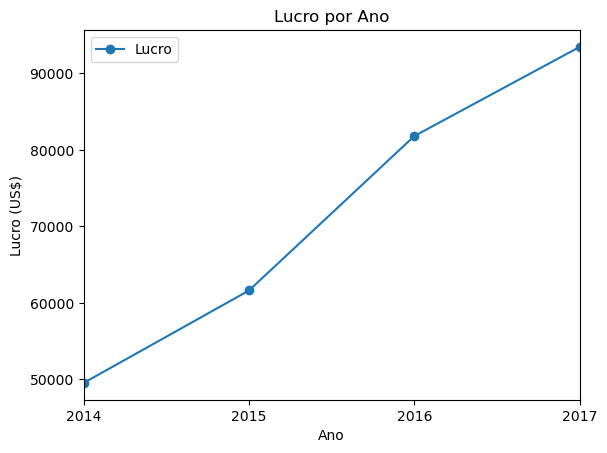

In [3]:
#Definindo o filtro do gráfico de lucro por Data do Pedido
lucro_anual = df.resample('YE', on='Data_Pedido')['Lucro'].sum().reset_index()

#Plotando o gráfico
graf_lucro_anual = lucro_anual.plot(x='Data_Pedido', y='Lucro', marker='o')
plt.title('Lucro por Ano')
plt.xlabel('Ano')
plt.ylabel('Lucro (US$)')
plt.show()

> **Observação:** O gráfico de linha permite acompanhar a saúde financeira da empresa ano a ano, mostrando se as estratégias adotadas no passado trouxeram retornos positivos.

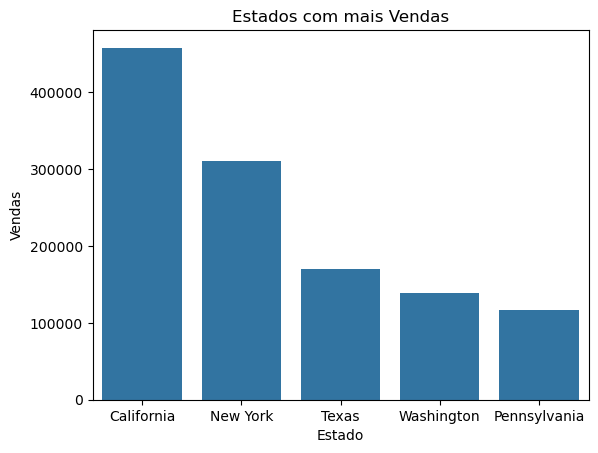

In [4]:
#Definindo filtro do gráfico dos 5 estados com mais vendas
estados_vendas = df.groupby('Estado')['Vendas'].sum().sort_values(ascending=False).head(5).reset_index()

#Plotando o gráfico
graf_estados_vendas = sns.barplot(data=estados_vendas, x='Estado', y='Vendas')
plt.title('Estados com mais Vendas')
plt.show()

## 4. Eficiência Operacional: Margem de Lucro Média
Para conectar o volume de vendas com o lucro real, analisamos a margem de lucro. A tabela abaixo detalha a eficiência financeira de cada categoria, mostrando o quanto do valor vendido realmente se converte em resultado positivo.

In [5]:
#Exibindo a Margem de Lucro de cada Categoria
df.groupby('Categoria')['Margem de Lucro %'].mean().round(2).reset_index()

,Categoria,Margem de Lucro %
0,Materiais de Escritorio,13.80
1,Mobilia,3.88
2,Tecnologia,15.61


> **Descoberta:** A tabela revela discrepâncias importantes. Algumas categorias podem ter um volume de vendas altíssimo (como visto no primeiro gráfico), mas apresentam uma margem de lucro baixa ou até negativa, exigindo atenção da gestão.

## 5. A Causa Raiz: O Impacto dos Descontos no Lucro
Para entender o motivo das variações na margem de lucro, cruzamos o lucro absoluto com as faixas de desconto aplicadas aos clientes. A linha vermelha tracejada marca o limite exato entre o lucro e o prejuízo.

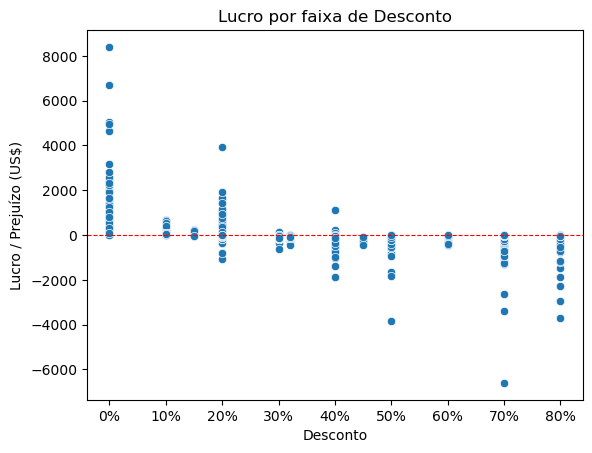

In [6]:
#Lucro por Faixa de Desconto
lucro_desconto = sns.scatterplot(data=df, x='Desconto', y='Lucro')
plt.title('Lucro por faixa de Desconto')
plt.xlabel('Desconto')
plt.ylabel('Lucro / Prejuízo (US$)')

#Exibindo os descontos em % manualmente
eixox_luc_desc = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
porc_eixox_luc_desc = ['0%', '10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%']
plt.xticks(eixox_luc_desc, porc_eixox_luc_desc)

#Exibindo uma linha de grade no eixo 0 para melhor visualização de Lucro (+) ou Prejuízo (-)
plt.axhline(y=0, color='red', linewidth='0.8', linestyle='--')
plt.show()

> **Descoberta:** Fica visualmente claro que descontos acima de 20% (0.2) começam a arrastar um grande volume de pedidos para a zona de prejuízo (abaixo da linha tracejada), especialmente em certas categorias de produtos.

## 6. Resultados da Análise e Conclusão
Com base na análise exploratória sequencial, recomendamos à gestão:
- **Revisão da Tabela de Descontos:** Estabelecer um teto máximo para concessão de descontos, evitando que as vendas cruzem a linha de prejuízo identificada.
- **Foco na Margem, não apenas no volume:** Reavaliar as categorias que mais vendem, mas que apresentam baixa margem de lucro média, otimizando custos e repensando a estratégia de preços.